# 04.09 — Propiedad de las medias, bolas de calor y regularidad interior

## 04.09.0 — Orden de esta colección

Este es el **Notebook 09** de la secuencia revisada.

La fuente principal es la página 3 de `Calor.pdf`, cuyo bloque izquierdo está titulado **Propiedad de las medias**.

Su correspondencia con el temario oficial es

$$
\boxed{\text{continuación del tema 4.7: regularidad}}
$$

En esta entrega se desarrolla una sola unidad conceptual:

$$
\boxed{\text{geometría de las bolas de calor y propiedad de las medias}}
$$

El teorema de Widder, escrito en la columna derecha de la misma página, se reserva para el notebook siguiente.


## 04.09.1 — Transcripción literal normalizada de las notas

### **Propiedad de las medias**

Sea

$$
\Omega\subset\mathbb R^n
$$

abierto y acotado, sea

$$
T>0,
$$

y escribamos

$$
\Omega_T=\Omega\times(0,T].
$$

La frontera parabólica es

$$
\Gamma_T
=
\overline{\Omega_T}\setminus\Omega_T.
$$

Para

$$
x\in\mathbb R^n,
\qquad
t>0,
\qquad
r>0,
$$

las notas definen la **bola de calor**

$$
B(x,t;r)
=
\left\{
(y,s)\in\mathbb R^n\times\mathbb R:
s<t,\ 
\psi(x-y,t-s)\geq\frac{1}{r^n}
\right\}.
$$

A continuación aparece el lema de la propiedad de las medias:

si

$$
u\in C^{2,1}(\Omega_T)
$$

satisface

$$
u_t-\Delta u=0
$$

en

$$
\Omega_T,
$$

entonces

$$
u(x,t)
=
\frac{1}{4r^n}
\iint_{B(x,t;r)}
u(y,s)
\frac{|x-y|^2}{(t-s)^2}
\,dy\,ds
$$

para toda bola de calor

$$
B(x,t;r)\subset\Omega_T.
$$

Finalmente, las notas indican que la propiedad de las medias caracteriza la ecuación del calor.

> **Nota de transcripción.**
> Se conservan la notación \(B(x,t;r)\), el factor \(1/(4r^n)\) y el peso
> $$
> \frac{|x-y|^2}{(t-s)^2}.
> $$
> Se sustituyó la desigualdad manuscrita no estricta por \(s<t\) para evitar el punto singular del núcleo. Esta modificación no altera la región salvo en su frontera.


## 04.09.2 — Geometría explícita de una bola de calor

Recordemos

$$
\psi(z,\tau)
=
\frac{1}{(4\pi\tau)^{n/2}}
\exp\!\left(
-\frac{|z|^2}{4\tau}
\right),
\qquad
\tau>0.
$$

La condición

$$
\psi(x-y,t-s)\geq\frac{1}{r^n}
$$

equivale a

$$
|x-y|^2
\leq
2n(t-s)
\log\!\left(
\frac{r^2}{4\pi(t-s)}
\right).
$$

Por tanto, necesariamente

$$
0<t-s\leq\frac{r^2}{4\pi}.
$$

Cada corte temporal

$$
s=t-\tau
$$

de la bola de calor es una bola espacial centrada en

$$
x
$$

y de radio

$$
R_r(\tau)
=
\sqrt{
2n\tau
\log\!\left(
\frac{r^2}{4\pi\tau}
\right)
}.
$$

La región está completamente situada en el pasado de

$$
(x,t).
$$


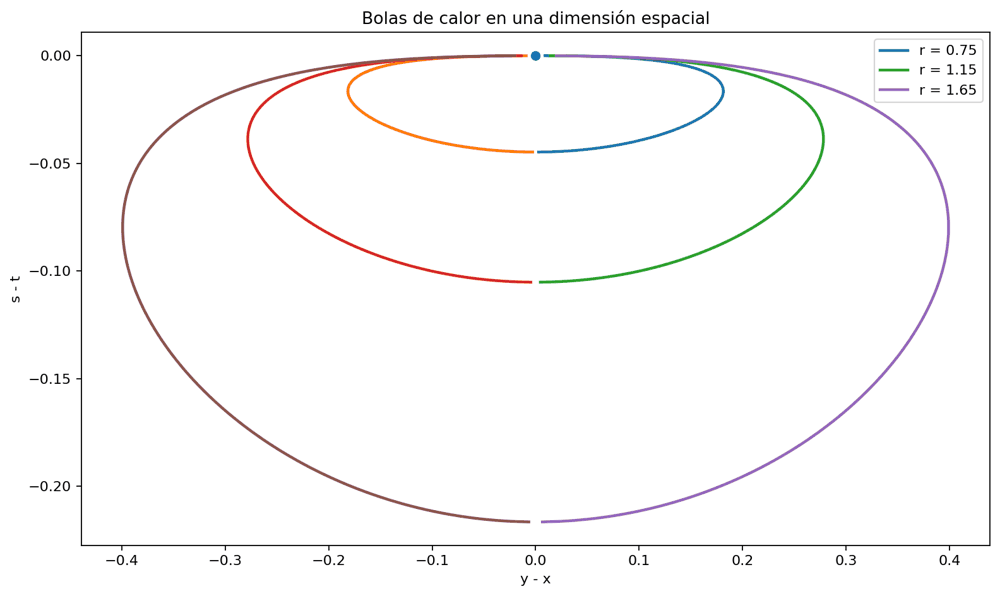

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def half_width(tau, radius, dimension=1):
    value = 2.0 * dimension * tau * np.log(
        radius**2 / (4.0 * np.pi * tau)
    )
    return np.sqrt(np.maximum(value, 0.0))

plt.figure(figsize=(10, 6), dpi=160)

for radius in [0.75, 1.15, 1.65]:
    tau_max = radius**2 / (4.0 * np.pi)
    tau = np.linspace(tau_max * 1.0e-4, tau_max * (1.0 - 1.0e-4), 900)
    width = half_width(tau, radius)
    plt.plot(width, -tau, linewidth=2, label=f"r = {radius}")
    plt.plot(-width, -tau, linewidth=2)

plt.scatter([0.0], [0.0], s=35)
plt.xlabel("y - x")
plt.ylabel("s - t")
plt.title("Bolas de calor en una dimensión espacial")
plt.legend()
plt.tight_layout()
plt.show()


## 04.09.3 — Normalización del promedio

### **Lema 04.09.1 — El peso tiene masa uno**

Para toda bola de calor

$$
B(x,t;r),
$$

se cumple

$$
\frac{1}{4r^n}
\iint_{B(x,t;r)}
\frac{|x-y|^2}{(t-s)^2}
\,dy\,ds
=
1.
$$

### Demostración

La función constante

$$
u(y,s)=1
$$

satisface

$$
u_s-\Delta u=0.
$$

Aplicando la propiedad de las medias a esta solución se obtiene

$$
1
=
\frac{1}{4r^n}
\iint_{B(x,t;r)}
\frac{|x-y|^2}{(t-s)^2}
\,dy\,ds.
$$

> **Aclaración.**
> Esta demostración usa el teorema de medias. La misma identidad puede verificarse directamente mediante coordenadas polares y el cambio
> $$
> \tau=t-s.
> $$


## 04.09.4 — Identidad de flujo

### **Lema 04.09.2 — Identidad espacio-temporal de Green**

Fijemos un punto

$$
(x,t)
$$

y definamos, para

$$
s<t,
$$

$$
\Phi(y,s)=\psi(x-y,t-s).
$$

Entonces

$$
\Phi_s+\Delta_y\Phi=0.
$$

Si

$$
u_s-\Delta_y u=0,
$$

el campo espacio-temporal

$$
\mathcal F(y,s)
=
\left(
\Phi\nabla_y u-u\nabla_y\Phi,
-u\Phi
\right)
$$

tiene divergencia nula:

$$
\operatorname{div}_{y,s}\mathcal F=0.
$$

### Demostración

Calculamos

$$
\begin{aligned}
\operatorname{div}_{y,s}\mathcal F
&=
\operatorname{div}_y
\left(
\Phi\nabla_yu-u\nabla_y\Phi
\right)
-
\partial_s(u\Phi)
\\[2mm]
&=
\Phi\Delta_yu-u\Delta_y\Phi
-u_s\Phi-u\Phi_s
\\[2mm]
&=
\Phi(\Delta_yu-u_s)
-u(\Delta_y\Phi+\Phi_s)
\\[2mm]
&=
0.
\end{aligned}
$$


## 04.09.5 — Propiedad de las medias

### **Teorema 04.09.3 — Propiedad de las medias para la ecuación del calor**

Sea

$$
u\in C^{2,1}(\Omega_T)
$$

una solución de

$$
u_t-\Delta u=0
$$

en

$$
\Omega_T.
$$

Supongamos que

$$
\overline{B(x,t;r)}
\subset\Omega_T.
$$

Entonces

$$
\boxed{
u(x,t)
=
\frac{1}{4r^n}
\iint_{B(x,t;r)}
u(y,s)
\frac{|x-y|^2}{(t-s)^2}
\,dy\,ds
}.
$$


### Demostración

Definimos

$$
\Phi(y,s)=\psi(x-y,t-s).
$$

La frontera lateral de la bola de calor es el conjunto de nivel

$$
\Phi(y,s)=\frac{1}{r^n}.
$$

Para evitar el polo situado en

$$
(x,t),
$$

consideramos una región truncada en la que

$$
t-s\geq\varepsilon.
$$

Aplicamos el teorema de la divergencia al campo

$$
\mathcal F
=
\left(
\Phi\nabla_y u-u\nabla_y\Phi,
-u\Phi
\right)
$$

del Lema 04.09.2.

Como

$$
\operatorname{div}_{y,s}\mathcal F=0,
$$

la suma de los flujos sobre las distintas componentes de la frontera es cero.

Sobre la frontera de nivel

$$
\Phi=\frac{1}{r^n},
$$

el vector normal es proporcional al gradiente espacio-temporal de

$$
\Phi.
$$

Al sustituir las derivadas explícitas del núcleo,

$$
\nabla_y\Phi
=
\frac{x-y}{2(t-s)}\Phi
$$

y

$$
\Phi_s
=
\left(
\frac{n}{2(t-s)}
-
\frac{|x-y|^2}{4(t-s)^2}
\right)\Phi,
$$

los términos tangenciales se cancelan y el flujo lateral se reduce al promedio ponderado

$$
\frac{1}{4r^n}
\iint_{B(x,t;r)}
u(y,s)
\frac{|x-y|^2}{(t-s)^2}
\,dy\,ds.
$$

La contribución de la tapa truncada converge a

$$
u(x,t)
$$

cuando

$$
\varepsilon\downarrow0,
$$

porque el núcleo del calor es una aproximación de la identidad.

Pasando al límite se obtiene la fórmula.


> **Complemento añadido — detalle técnico de la demostración.**
>
> La conversión del flujo sobre las superficies de nivel en una integral sobre la bola se realiza mediante la fórmula de coárea. Éste es el paso que produce exactamente el factor
>
> $$
> \frac{|x-y|^2}{4r^n(t-s)^2}.
> $$
>
> La nota manuscrita registra la fórmula final, pero no desarrolla este cálculo geométrico.


## 04.09.6 — Subsoluciones y desigualdad de medias

### **Proposición 04.09.4 — Desigualdad de medias**

Sea

$$
u\in C^{2,1}(\Omega_T)
$$

y supongamos que

$$
u_t-\Delta u\leq0
$$

en

$$
\Omega_T.
$$

Entonces, para toda bola de calor compactamente contenida en el dominio,

$$
\boxed{
u(x,t)
\leq
\frac{1}{4r^n}
\iint_{B(x,t;r)}
u(y,s)
\frac{|x-y|^2}{(t-s)^2}
\,dy\,ds
}.
$$

### Justificación

En la identidad de flujo del Lema 04.09.2 aparece ahora el término

$$
\Phi(\Delta u-u_t)\geq0.
$$

Por tanto, la igualdad de flujo se transforma en la desigualdad indicada.


## 04.09.7 — Caracterización de las funciones calóricas

### **Proposición 04.09.5 — Recíproco de la propiedad de las medias**

Sea

$$
u\in C^{2,1}(\Omega_T).
$$

Supongamos que, para todo punto

$$
(x,t)\in\Omega_T
$$

y todo radio suficientemente pequeño,

$$
u(x,t)
=
\frac{1}{4r^n}
\iint_{B(x,t;r)}
u(y,s)
\frac{|x-y|^2}{(t-s)^2}
\,dy\,ds.
$$

Entonces

$$
u_t-\Delta u=0
$$

en

$$
\Omega_T.
$$

### Demostración

Supongamos, por contradicción, que existe

$$
(x_0,t_0)\in\Omega_T
$$

tal que

$$
u_t(x_0,t_0)-\Delta u(x_0,t_0)>0.
$$

Por continuidad, existe una vecindad parabólica en la que

$$
u_t-\Delta u>0.
$$

En dicha vecindad,

$$
u
$$

es una supersolución estricta.

La versión estricta de la desigualdad de medias proporciona, para radios pequeños,

$$
u(x_0,t_0)
>
\frac{1}{4r^n}
\iint_{B(x_0,t_0;r)}
u(y,s)
\frac{|x_0-y|^2}{(t_0-s)^2}
\,dy\,ds,
$$

en contradicción con la hipótesis de igualdad.

El caso

$$
u_t-\Delta u<0
$$

se descarta de manera análoga.

Por tanto,

$$
u_t-\Delta u=0.
$$


## 04.09.8 — Consecuencia local del principio fuerte del máximo

### **Corolario 04.09.6**

Sea

$$
u
$$

calórica en una vecindad de

$$
\overline{B(x,t;r)}.
$$

Supongamos que

$$
u\leq M
$$

en la bola de calor y que

$$
u(x,t)=M.
$$

Entonces

$$
u(y,s)=M
$$

para todo

$$
(y,s)\in B(x,t;r).
$$

### Demostración

La propiedad de las medias da

$$
M
=
\frac{1}{4r^n}
\iint_{B(x,t;r)}
u(y,s)
\frac{|x-y|^2}{(t-s)^2}
\,dy\,ds.
$$

El peso es no negativo y tiene masa uno.

Como

$$
u\leq M,
$$

el promedio sólo puede ser igual a

$$
M
$$

si

$$
u=M
$$

en toda la región donde el peso es positivo.

La continuidad extiende la igualdad a toda la bola de calor.


## 04.09.9 — Núcleo de medias suavizado

La fórmula de las notas integra sobre una región cuya frontera depende del punto central.

Para obtener estimaciones de derivadas es conveniente promediar la fórmula respecto del radio.

### **Lema 04.09.7 — Representación local por un núcleo suave**

Sea

$$
Q_{2r}^-(x_0,t_0)
=
B_{2r}(x_0)\times(t_0-4r^2,t_0]
$$

compactamente contenido en

$$
\Omega_T.
$$

Existe un núcleo no negativo

$$
K_r\in C_c^\infty(\mathbb R^n\times(-\infty,0))
$$

tal que, para todo

$$
(x,t)\in Q_r^-(x_0,t_0),
$$

$$
u(x,t)
=
\iint
K_r(y,s)
u(x-y,t-s)
\,dy\,ds.
$$

Además,

$$
K_r(y,s)
=
r^{-(n+2)}
K_1\!\left(
\frac{y}{r},
\frac{s}{r^2}
\right).
$$

> **Complemento añadido.**
> El núcleo \(K_r\) se obtiene promediando la propiedad de las medias para radios comprendidos entre dos múltiplos fijos de \(r\), con una función de corte suave.


## 04.09.10 — Regularidad interior

### **Teorema 04.09.8 — Estimaciones interiores para funciones calóricas**

Sea

$$
u\in C^{2,1}(\Omega_T)
$$

una solución de

$$
u_t-\Delta u=0.
$$

Supongamos que

$$
Q_{2r}^-(x_0,t_0)
\subset\subset\Omega_T.
$$

Entonces

$$
u\in C^\infty\!\left(Q_r^-(x_0,t_0)\right).
$$

Para todo multiíndice

$$
\alpha
$$

y todo entero

$$
m\geq0,
$$

existe una constante

$$
C_{\alpha,m,n}>0
$$

tal que

$$
\boxed{
\sup_{Q_r^-(x_0,t_0)}
\left|
D_x^\alpha\partial_t^m u
\right|
\leq
C_{\alpha,m,n}
r^{-|\alpha|-2m}
\sup_{Q_{2r}^-(x_0,t_0)}
|u|
}.
$$


### Demostración

Usamos la representación del Lema 04.09.7:

$$
u(x,t)
=
\iint
K_r(y,s)
u(x-y,t-s)
\,dy\,ds.
$$

El núcleo es suave y compacto, por lo que podemos diferenciar respecto del punto central:

$$
D_x^\alpha\partial_t^m u(x,t)
=
\iint
D_y^\alpha\partial_s^m K_r(y,s)
u(x-y,t-s)
\,dy\,ds,
$$

salvo un signo irrelevante en cada derivación, que desaparece al tomar valores absolutos.

El escalamiento parabólico de

$$
K_r
$$

implica

$$
D_y^\alpha\partial_s^m K_r(y,s)
=
r^{-(n+2+|\alpha|+2m)}
\left(
D_y^\alpha\partial_s^mK_1
\right)
\left(
\frac{y}{r},
\frac{s}{r^2}
\right).
$$

Por tanto,

$$
\left\|
D_y^\alpha\partial_s^mK_r
\right\|_{L^1}
\leq
C_{\alpha,m,n}
r^{-|\alpha|-2m}.
$$

Finalmente,

$$
\begin{aligned}
\left|
D_x^\alpha\partial_t^m u(x,t)
\right|
&\leq
\left\|
D_y^\alpha\partial_s^mK_r
\right\|_{L^1}
\sup_{Q_{2r}^-}|u|
\\[2mm]
&\leq
C_{\alpha,m,n}
r^{-|\alpha|-2m}
\sup_{Q_{2r}^-}|u|.
\end{aligned}
$$

Como esta estimación vale para todos los órdenes, se concluye que

$$
u\in C^\infty
$$

en el interior.


### **Corolario 04.09.9 — Hiporregularidad del operador del calor**

Toda solución distribucional local de

$$
u_t-\Delta u=0
$$

es infinitamente diferenciable.

> **Complemento añadido.**
> Para pasar de una solución distribucional a una solución suave se regulariza primero con mollificadores espacio-temporales, se aplican las estimaciones interiores a las regularizaciones y se pasa al límite. Este resultado expresa que el operador del calor es hipoelíptico.


## 04.09.11 — Animación Manim

Ejecuta la gráfica estática y después la siguiente celda para renderizar y reproducir el MP4 en este cuaderno.

In [ ]:
from pathlib import Path
from runpy import run_path
carpeta = Path.cwd()
if (carpeta / "calor").is_dir():
    carpeta = carpeta / "calor"
# Ejecuta primero la gráfica estática de esta unidad.
renderizar = run_path(str(carpeta / "manim" / "perfiles.py"))["renderizar_perfiles"]

def perfiles(t):
    tau = np.linspace(1e-7, t**2/(4*np.pi), 360)
    ancho = half_width(tau, t)
    return [(ancho,-tau),(-ancho,-tau)]

renderizar("Bolas de calor", perfiles, (0.75,1.65), [-0.6,0.6,0.2], [-0.24,0,0.05],
           ['Rama derecha','Rama izquierda'], eje_x="posición", eje_y="tiempo relativo", parametro="radio")

## 04.09.12 — Ejercicios de práctica sin solución

### **Ejercicio 04.09.1 — Cortes espaciales de una bola de calor**

Demuestre que el corte de

$$
B(x,t;r)
$$

en el tiempo

$$
s=t-\tau
$$

es una bola espacial de radio

$$
R_r(\tau)
=
\sqrt{
2n\tau
\log\!\left(
\frac{r^2}{4\pi\tau}
\right)
}.
$$

Determine el valor de

$$
\tau
$$

para el cual este radio es máximo.

---

### **Ejercicio 04.09.2 — Escalamiento parabólico**

Demuestre que

$$
(y,s)\in B(x,t;r)
$$

si y sólo si

$$
\left(
\frac{y-x}{r},
\frac{s-t}{r^2}
\right)
\in
B(0,0;1).
$$

---



## 04.09.13 — Avance respecto del temario

Con esta entrega se completó la unidad de regularidad formada por los notebooks 08 y 09:

$$
\boxed{\text{4.7 Regularidad}}.
$$

En el notebook 08 se estudiaron:

- derivadas del núcleo;
- suavizamiento instantáneo;
- estimaciones
  $$
  L^p\text{–}L^q;
  $$
- regularidad de la fórmula de Duhamel.

En este notebook se estudiaron:

- bolas de calor;
- propiedad de las medias;
- desigualdad de medias;
- caracterización de las funciones calóricas;
- consecuencia local del principio fuerte;
- estimaciones interiores;
- regularidad de soluciones distribucionales.

La siguiente sección será

$$
\boxed{\text{10 — Teorema de Widder}}.
$$

Esa sección transcribirá la columna derecha de la página 3 de las notas.
